# Exercise 1 

In this exercise, we will work with the `spam.csv` data file. This file contains text and a label attached to each text. The goal is to clean the text data and then build classifcation models. 

### Exercise 1(a) (2 points)

Load the `pandas` and `numpy` libraries.

In [1]:
import pandas as pd
import numpy as np

### Exercise 1(b) (2 points)

Read the `csv` file and create a data-frame called `spam_df`.

In [2]:
spam_df = pd.read_csv("spam.csv")
spam_df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Exercise 1(c) (2 points)

Using the `string` library, remove all the punctuation of the `text` column.

In [3]:
import string

spam_df ["text_clean"] = spam_df["text"].str.replace(f"[{string.punctuation}]", "", regex=True)
spam_df.head()

,label,text,text_clean
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...


### Exercise 1(d) (10 points)

Using the `nltk` library, remove stopwords and pronouns from `text_clean` and store in another column called `'text_clean_1'`. 

In [4]:
import nltk
nltk.download('stopwords')
nltk.download('punkt')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))
pronouns = ["i", "me", "my", "mine", "we", "us", "our", "ours", "you", "your", "yours", "he", "him", "his", "she", "her", "hers", "they", "them", "their", "theirs", "u", "ur", "urs", "im", "dont", "2" , "ill", "4"]


def clean_text(text):
    # Tokenize the text
    tokens = word_tokenize(text.lower())
    
     # replacing words
    tokens = [word.replace ('txt', 'text') for word in tokens]
    # remove stopwords and pronouns
    tokens = [word for word in tokens if word not in stop_words and word not in pronouns]

    return ' '.join(tokens)

spam_df['text_clean_1'] = spam_df['text'].apply(clean_text)
spam_df.head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\juani\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\juani\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


,label,text,text_clean,text_clean_1
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,"go jurong point , crazy .. available bugis n g..."
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar ... joking wif oni ...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor ... c already say ...
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,"nah n't think goes usf , lives around though"


### Exercise 1(e) (10 points)

Perform Lemmatization of `text_clean_1` and store the results in another column called `text_clean_2` in the `spam_df` data frame.

In [6]:
import nltk
from nltk.corpus import wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(word):
    """Map POS tag to first character lemmatize() accepts"""
    tag = nltk.pos_tag([word])[0][1][0].upper()
    tag_dict = {"J": wordnet.ADJ,
                "N": wordnet.NOUN,
                "V": wordnet.VERB,
                "R": wordnet.ADV}
    return tag_dict.get(tag, wordnet.NOUN)

def lemmatize_text(text):
    tokens = word_tokenize(text)
    lemmatized_tokens = [lemmatizer.lemmatize(token, get_wordnet_pos(token)) for token in tokens]
    return ' '.join(lemmatized_tokens)

spam_df['text_clean_2'] = spam_df['text_clean_1'].apply(lemmatize_text)
spam_df.head()

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\juani\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\juani\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


,label,text,text_clean,text_clean_1,text_clean_2
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,"go jurong point , crazy .. available bugis n g...","go jurong point , crazy .. available bugis n g..."
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar ... joking wif oni ...,ok lar ... joking wif oni ...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts 21s...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor ... c already say ...,dun say early hor ... c already say ...
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,"nah n't think goes usf , lives around though","nah n't think go usf , life around though"


### Exercise 1(f) (5 points)

Based on the results from part 1(f), we see digits in some of the text in `text_clean_2`. Remove all the digits from `text_clean_2` and store the results in another column `text_clean_3` in the `spam_df` data frame.

In [7]:
import re

# function to remove numbers from text
def remove_numbers(text):
    return re.sub(r'\d+', '', text)

spam_df['text_clean_3'] = spam_df['text_clean_2'].apply(remove_numbers)
spam_df.head()

,label,text,text_clean,text_clean_1,text_clean_2,text_clean_3
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,"go jurong point , crazy .. available bugis n g...","go jurong point , crazy .. available bugis n g...","go jurong point , crazy .. available bugis n g..."
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar ... joking wif oni ...,ok lar ... joking wif oni ...,ok lar ... joking wif oni ...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts st ...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor ... c already say ...,dun say early hor ... c already say ...,dun say early hor ... c already say ...
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,"nah n't think goes usf , lives around though","nah n't think go usf , life around though","nah n't think go usf , life around though"


### Exercise 1(g) (10 points) LDA (Latent Dirichlet Allocation) Feature Generation

Generate LDA features based on five topics. Use `TfidfVectorizer` to generate `TF-IDF` features with the following configuration:

```
tfidf_vectorizer = TfidfVectorizer(
    max_features=100,
    max_df=0.8,  # Remove words that appear in more than 80% of documents
    min_df=5,    # Remove words that appear in fewer than 5 documents
    stop_words='english'
)
```

Then, extract five topics using `LatentDirichletAllocation` with the following configuration:

```
# Initialize LDA with 5 topics
n_topics = 5
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=100,
    learning_method='batch'
)
```

Then, print the words associated to each of the topics.

In [8]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=100,
    max_df=0.8,  # Remove words that appear in more than 80% of documents
    min_df=5,    # Remove words that appear in fewer than 5 documents
    stop_words='english'
)

# fit and transform the cleaned text to create the TF-IDF matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(spam_df['text_clean_3'])
print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")
print(f"Number of features: {len(tfidf_vectorizer.get_feature_names_out())}")

TF-IDF matrix shape: (5572, 100)
Number of features: 100


In [9]:
n_topics = 5
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=100,
    learning_method='batch'
)

# fit the LDA model to the TF-IDF matrix
lda_topic_features = lda_model.fit_transform(tfidf_matrix)

print(f"LDA topic features shape: {lda_topic_features.shape}")
print(lda_topic_features[:5])

LDA topic features shape: (5572, 5)
[[0.08284465 0.08284475 0.37794925 0.37162985 0.08473151]
 [0.10000007 0.10000008 0.10000008 0.59999971 0.10000006]
 [0.70173789 0.07456553 0.07456552 0.07456556 0.07456549]
 [0.10000031 0.10199081 0.10095281 0.10150287 0.5955532 ]
 [0.08300062 0.084412   0.08300069 0.39911093 0.35047575]]


In [12]:
# function to display the top words for each LDA topic

def display_lda_topics(model, feature_names, n_top_words):
    for topic_idx, topic in enumerate(model.components_):
        print(f"Topic {topic_idx}:")
        print("".join ([feature_names[i] for i in topic.argsort()[:-n_top_words - 1:-1]]))
        print()

# display the top words for each LDA topic
n_top_words = 10
display_lda_topics(lda_model, tfidf_vectorizer.get_feature_names_out(), n_top_words)

Topic 0:
textfreedearstopreplymobilemsgyeahmessagelol

Topic 1:
knowtimeneedaskohheynawaitrightlet

Topic 2:
llcomegtltlikedalaterhiwatnight

Topic 3:
okhomelorì_waylovetomorrowsorrywatchpick

Topic 4:
gooddaywanttodaymakeworkthinkyesmisstell



### Exercise 1(h) (10 points) NMF (Non-negative Matrix Factorization) Feature Generation

Generate NMF features based on five topics. Consider the following configuration for the `NMF`:

```
# Initialize NMF with the same number of topics as LDA for comparison
nmf_model = NMF(
    n_components=n_topics,
    random_state=42,
    max_iter=200,
    alpha_W=0,    # Regularization parameter for W
    alpha_H=0,    # Regularization parameter for H
    l1_ratio=0.5    # Balance between L1 and L2 regularization
)
```

Then, print the words associated to each topic.

In [13]:
from sklearn.decomposition import NMF

nmf_model = NMF(
    n_components=n_topics,
    random_state=42,
    max_iter=200,
    alpha_W=0,    # Regularization parameter for W
    alpha_H=0,    # Regularization parameter for H
    l1_ratio=0.5    # Balance between L1 and L2 regularization
)

# fit the NMF model to the TF-IDF matrix
nmf_topic_features = nmf_model.fit_transform(tfidf_matrix)

print(f"NMF topic features shape: {nmf_topic_features.shape}")
print(nmf_topic_features[:5])

NMF topic features shape: (5572, 5)
[[0.00057659 0.00133953 0.00569949 0.00352064 0.03053926]
 [0.         0.         0.31061777 0.         0.        ]
 [0.11997336 0.         0.         0.         0.        ]
 [0.         0.00624313 0.01759079 0.         0.06748719]
 [0.         0.         0.         0.         0.05354027]]


In [14]:
print(f"NMF Topic with top words")
display_lda_topics(nmf_model, tfidf_vectorizer.get_feature_names_out(), n_top_words)


NMF Topic with top words
Topic 0:
textfreestopmobilereplyphonewwwwinnewmin

Topic 1:
gtltminsendsaylikefriendmsgsenttime

Topic 2:
oklorsayaskwanwatì_leavemsghome

Topic 3:
comehomewanttimetomorrowì_askpicktellda

Topic 4:
knowlllikegooddaylovetimesorrylaterneed



### Exercise 1(i) (10 points) Using Topic Features for Classification

Train and evaluate three `LogisticRegression` models as follows:

- Using LDA features as input.
- Using NMF features as input.
- Combine LDA + NMF features as input.

Evaluate the three models over a five-fold cross validation strategy.

In [15]:
from sklearn.model_selection import StratifiedKFold , cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

y = spam_df ['label'].map({'ham': 0, 'spam': 1})

# LDA features only
X_lda = lda_topic_features
# NMF features only
X_nmf = nmf_topic_features
# Combined LDA and NMF features
X_combined = np.hstack([X_lda, X_nmf])

print(" Comparing classification performance using different topic features")
print ("=" * 60)
# cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))

# evaluate each feature
feature_sets = {
    "LDA": X_lda,
    "NMF": X_nmf,
    "Combined": X_combined
}

results = {}
for name, X in feature_sets.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy')
    results[name] = scores
    print(f"{name} features: Mean accuracy = {scores.mean():.4f}, Std = {scores.std():.4f}")

print("=" * 60)
print("Summary of results:")
for name, scores in results.items():
    print(f"{name} features: Mean accuracy = {scores.mean():.4f}, Std = {scores.std():.4f}")

 Comparing classification performance using different topic features
LDA features: Mean accuracy = 0.9067, Std = 0.0105
NMF features: Mean accuracy = 0.9171, Std = 0.0060
Combined features: Mean accuracy = 0.9370, Std = 0.0049
Summary of results:
LDA features: Mean accuracy = 0.9067, Std = 0.0105
NMF features: Mean accuracy = 0.9171, Std = 0.0060
Combined features: Mean accuracy = 0.9370, Std = 0.0049


### Exercise 1(j) (15 points) K-means + BERT Topic Modeling

Generate topic features using K-means clustering on BERT embeddings. This approach:
1. Uses BERT to create dense semantic embeddings of the text
2. Applies K-means clustering to group similar documents
3. Creates features based on cluster assignments and distances

This method often captures semantic relationships better than traditional bag-of-words approaches.

In [17]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

C:\Users\juani\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [19]:
print ("Loading Bert Model....")

# using a smaller, faster model for illustration purposes
bert_model = SentenceTransformer("all-MiniLM-L6-v2")

bert_embeddings = bert_model.encode(
    spam_df['text_clean_3'].tolist(),
    show_progress_bar=True,
    batch_size=32
)

print(f"Bert embeddings shape: {bert_embeddings.shape}")
print(f" Each document is represented by a {bert_embeddings.shape[1]}-dimensional vector")


Loading Bert Model....


c:\Users\juani\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\juani\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\juani\AppData\Local\Programs\Python\Python312\Lib\site-packages\hu

Bert embeddings shape: (5572, 384)
 Each document is represented by a 384-dimensional vector


For n_clusters = 2, Inertia = 4643.98, Silhouette: 0.029
For n_clusters = 3, Inertia = 4570.03, Silhouette: 0.022
For n_clusters = 4, Inertia = 4513.74, Silhouette: 0.022
For n_clusters = 5, Inertia = 4470.75, Silhouette: 0.018
For n_clusters = 6, Inertia = 4433.58, Silhouette: 0.019
For n_clusters = 7, Inertia = 4400.60, Silhouette: 0.019
For n_clusters = 8, Inertia = 4368.92, Silhouette: 0.019
For n_clusters = 9, Inertia = 4346.82, Silhouette: 0.017
For n_clusters = 10, Inertia = 4326.01, Silhouette: 0.018


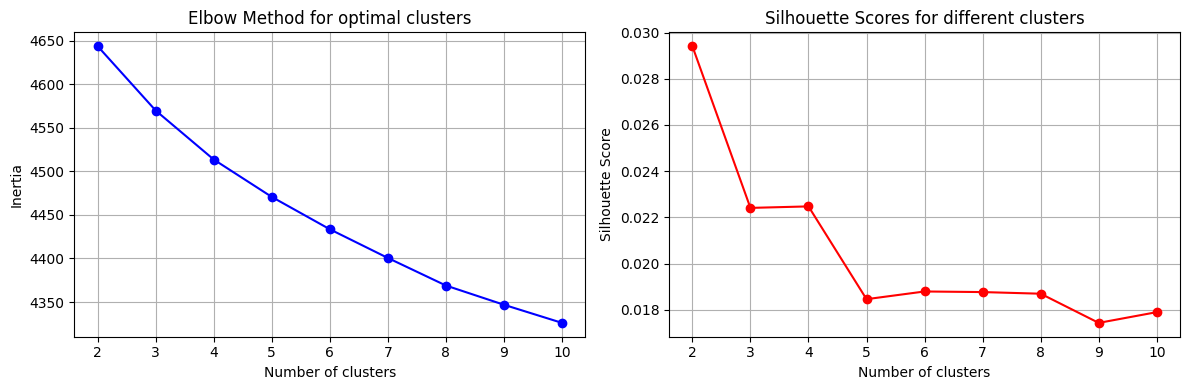


 optimal number of clusters: 2


In [22]:
import matplotlib.pyplot as plt

# test different numbers of cluster
cluster_range = range(2, 11)
inertias = []
silhouette_scores = []
for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(bert_embeddings)

    inertias.append(kmeans.inertia_)
    silhouette_avg = silhouette_score(bert_embeddings, cluster_labels)
    silhouette_scores.append(silhouette_avg)

    print(f"For n_clusters = {n_clusters}, Inertia = {kmeans.inertia_:.2f}, Silhouette: {silhouette_avg:.3f}")

    # plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# elbow plot
ax1.plot(cluster_range, inertias, color='b', marker='o')
ax1.set_title('Elbow Method for optimal clusters')
ax1.set_xlabel('Number of clusters')
ax1.set_ylabel('Inertia')
ax1.grid(True)

# silhouette score plot
ax2.plot(cluster_range, silhouette_scores, color='r', marker='o')
ax2.set_xlabel('Number of clusters') 
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Scores for different clusters')
ax2.grid(True)

plt.tight_layout()
plt.show()

optimal_clusters = cluster_range[np.argmax(silhouette_scores)]
print(f"\n optimal number of clusters: {optimal_clusters}")
